# 03 · Regresión supervisada (Paso 07)

**Pregunta:** ¿cuántos siniestros con víctimas ocurrirán en cada barrio el mes siguiente?

**Protocolo:** [docs/experimental_protocol.md](../docs/experimental_protocol.md), que se fijó antes de este notebook. **Informe y dictamen:** [docs/regression_report.md](../docs/regression_report.md).

| Elemento | Definición |
|---|---|
| Filas | Barrio × mes objetivo; variables con información hasta L = T − 1 (gap = 0) |
| Validación | Expansiva: V2022, V2023 y V2024 |
| Test principal | 2025, reservado para la evaluación de la selección congelada con gap = 0. Las secciones 4b y 5 presentan análisis exploratorios separados. |
| Métrica principal | MAE. Secundarias: devianza de Poisson, sesgo, MAE por barrio y por período, cobertura de los intervalos de la binomial negativa |
| Criterio de mejora | En validación: MAE ≤ 0,97 × el mejor baseline y mejor en al menos 2 de 3 *folds*. En test: IC 95 % por bloques de ΔMAE < 0 |
| Candidatos | Poisson L2 (20 configuraciones), binomial negativa NB2 (2) y HGB con pérdida Poisson (16). Total: 38 (`src/regression.py`). Más 8 configuraciones post hoc de NB con L2 (§4b, no confirmatorias) |

**Orden de ejecución.** §1–§3 usan solo el desarrollo y **congelan la selección** en `seleccion_congelada.json`. La sección 4 lee esa selección y ejecuta la evaluación principal de 2025. Las secciones 4b y 5 reutilizan 2025 con fines exploratorios y conservan la selección congelada.

### Guía para el lector

**La pregunta, en una frase.** Si al cierre de cada mes quisiéramos saber cuántos siniestros con víctimas habrá en cada barrio el mes siguiente, ¿un modelo estadístico lo estima mejor que el simple promedio de los últimos 12 meses?

**Por qué importa.** Estimar cantidades permite dimensionar recursos (por ejemplo, controles o campañas) y no solo ordenar barrios. Pero si un promedio simple rinde igual, no se justifica la complejidad de un modelo.

**Cómo se mide.** Con el **MAE** (error absoluto medio): el promedio de cuántos hechos se equivoca el pronóstico por barrio y mes. Un MAE de 4 significa que, en promedio, el pronóstico se aleja 4 hechos de lo que ocurrió. Más bajo es mejor.

**Cómo se procede.**
1. Se calcula el MAE de tres referencias simples (§1).
2. Se prueban 38 configuraciones de modelos, de tres familias, en los años de validación 2022 a 2024 (§2).
3. Se elige la mejor **solo con la validación** y se congela antes de mirar 2025 (§3). Para declarar una mejora se exige un MAE al menos 3 % menor que el de la mejor referencia y ganar en 2 de los 3 años.
4. Se hace **una única** evaluación en 2025 (§4). Las §4b y §5 son análisis exploratorios que no cambian la elección.

**Resultado principal.** Gana un modelo de Poisson regularizado, entrenado sin los meses de pandemia. En 2025 su MAE es 4,071, frente a 4,062 del promedio de 12 meses: una diferencia de +0,009 hechos, con un intervalo de confianza que incluye el 0 (entre −0,127 y +0,142). **El modelo no supera al promedio de 12 meses**, aunque sí es claramente mejor que repetir el último mes (alrededor de 1 hecho menos de error por barrio y mes).

**Por qué este resultado negativo también es un hallazgo.** Indica que, a escala barrio × mes, casi toda la información útil ya está en el historial reciente (hallazgo E6). Una herramienta pública puede apoyarse en el promedio de 12 meses, que es transparente y fácil de mantener.

### Glosario de este notebook

| Término | Significado |
|---|---|
| **MAE; ΔMAE** | Error absoluto medio en hechos por barrio y mes; diferencia de MAE entre el modelo y una referencia. Un ΔMAE negativo favorece al modelo. |
| **Sesgo** | Error medio con signo. Un sesgo negativo indica que el modelo subestima. |
| **Devianza de Poisson** | Medida de error adecuada para conteos; complementa al MAE. |
| **Baselines** | Persistencia (repetir el último mes), estacional (repetir el mismo mes del año anterior) y media de 12 meses. |
| **Poisson L2 (α)** | Modelo lineal para conteos con penalización L2; α es la fuerza de la penalización. |
| **NB2** | Binomial negativa: como Poisson, pero admite más variabilidad (sobredispersión). |
| **HGB** | *Histogram gradient boosting*: modelo de árboles de decisión, aquí con pérdida de Poisson. |
| **`excluir_pandemia`** | Si es verdadero, el modelo se entrena sin los meses de pandemia (marzo de 2020 a mayo de 2021). |
| **Fold; selección congelada** | Año de validación (V2022, V2023 y V2024); configuración elegida y guardada en `seleccion_congelada.json` antes de mirar 2025. |
| **IC 95 % por bloques** | Intervalo de confianza que remuestrea bloques de 3 meses para respetar la dependencia entre meses consecutivos. Si incluye el 0, la diferencia no es concluyente. |
| **Intervalo de predicción; cobertura nominal** | Rango en el que debería caer el valor real con una probabilidad dada (80 % o 95 %); la cobertura observada indica si se cumple. |
| ***Post hoc*** | Análisis agregado después de ver el test. Se informa, pero no se usa para decidir. |
| ***Gap* = 1** | Sensibilidad que supone un mes de demora en la publicación de los datos. |
| **H2** | Hipótesis de la propuesta: un modelo mejora al historial en la estimación de conteos. |

## 0. Datos y particiones

> **Qué hace la celda siguiente.** Construye la tabla de variables del notebook 02 (con *gap* 0 y 1), agrega versiones logarítmicas de algunas variables y arma las particiones. **Qué mirar en la salida:** filas de entrenamiento y validación por año (1.152, 1.728 y 2.304 de entrenamiento; 576 de validación cada uno) y el ajuste final con 2.880 filas de entrenamiento y 576 de test.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import sys; sys.path.insert(0, str(ROOT))
from src import features as F, regression as R
from src.evaluation import regression_metrics, block_bootstrap_ci
warnings.filterwarnings("ignore")
FIG, TAB = ROOT / "reports" / "figures" / "03_regression", ROOT / "reports" / "tables" / "03_regression"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10})
panel = F.load_panel(); nbrs = F.queen_neighbors()
XG = {g: R.add_log_features(F.build_features(panel, nbrs, h=1, gap=g)) for g in (0, 1)}
X = XG[0]; folds = F.temporal_folds(X); tr_fin, te_fin = F.final_split(X)
M = {"configs_probadas": len(R.grid())}
print({fo["fold"]: (int(fo["train"].sum()), int(fo["val"].sum())) for fo in folds}, "| final", int(tr_fin.sum()), int(te_fin.sum()))

{'V2022': (1152, 576), 'V2023': (1728, 576), 'V2024': (2304, 576)} | final 2880 576


## 1. Baselines en validación

> **Qué hace la celda siguiente.** Calcula el MAE de las tres referencias simples en cada año de validación. **Qué mirar en la salida:** el promedio de 12 meses (`media12`, MAE 3,850) es la vara a superar, muy por delante de repetir el último mes (4,823) o el mismo mes del año anterior (5,157).

In [2]:
def eval_rows(Xd, mask, yhat, label, fold):
    m = regression_metrics(Xd.loc[mask, "y_target"], yhat); m.update({"modelo": label, "fold": fold}); return m
rows = []
for fo in folds:
    for b, col in R.BASELINES.items():
        rows.append(eval_rows(X, fo["val"], X.loc[fo["val"], col], f"baseline:{b}", fo["fold"]))
base_val = pd.DataFrame(rows)
bv = base_val.pivot(index="modelo", columns="fold", values="MAE"); bv["MAE_media"] = bv.mean(axis=1)
best_base = bv["MAE_media"].idxmin(); M["mejor_baseline"] = best_base
base_val.to_csv(TAB / "baselines_validacion.csv", index=False)
display(bv.round(3)); print("Mejor baseline (validación):", best_base)

fold,V2022,V2023,V2024,MAE_media
modelo,,,,
baseline:estacional,5.788,4.715,4.967,5.157
baseline:media12,3.918,3.730,3.901,3.850
baseline:persistencia,4.819,5.024,4.625,4.823


Mejor baseline (validación): baseline:media12


## 2. Búsqueda en grilla con validación expansiva

> **Qué hace la celda siguiente.** Entrena las 38 configuraciones en los tres años de validación, siempre con datos anteriores al año evaluado, y ordena los resultados por MAE medio. **Qué mirar en la salida:** las mejores son modelos de Poisson regularizados y entrenados sin los meses de pandemia.

In [3]:
res, preds_val = [], {}
t0 = time.time()
for kind, params in R.grid():
    name = R.config_name(kind, params)
    for fo in folds:
        trm = R.train_mask_excluding_pandemia(X, fo["train"], params["excluir_pandemia"])
        m = R.make_model(kind, params).fit(X.loc[trm], X.loc[trm, "y_target"])
        yhat = m.predict(X.loc[fo["val"]])
        r = eval_rows(X, fo["val"], yhat, name, fo["fold"]); r["familia"] = kind
        if kind == "negbin": r["alpha_nb"] = m.alpha_
        res.append(r); preds_val[(name, fo["fold"])] = yhat
grid_res = pd.DataFrame(res)
M["tiempo_grilla_s"] = round(time.time() - t0, 1)
summ = grid_res.groupby(["familia", "modelo"]).agg(MAE_media=("MAE", "mean"), devianza_media=("devianza_poisson", "mean"),
                                                    sesgo_medio=("sesgo", "mean")).reset_index()
wide = grid_res.pivot(index="modelo", columns="fold", values="MAE")
summ = summ.merge(wide, left_on="modelo", right_index=True).sort_values("MAE_media")
summ.to_csv(TAB / "grilla_validacion.csv", index=False)
print(f"{len(summ)} configuraciones × 3 folds en {M['tiempo_grilla_s']} s"); summ.head(12).round(4)

38 configuraciones × 3 folds en 20.1 s


,familia,modelo,MAE_media,devianza_media,sesgo_medio,V2022,V2023,V2024
25,poisson,"poisson|conjunto=compacto,alpha=0.1,excluir_pa...",3.8630,1.5895,-0.7418,3.9614,3.7282,3.8995
27,poisson,"poisson|conjunto=compacto,alpha=1.0,excluir_pa...",3.9329,1.6340,-0.8201,4.1883,3.6793,3.9310
37,poisson,"poisson|conjunto=completo,alpha=1.0,excluir_pa...",3.9978,1.7311,-0.9707,4.4294,3.6785,3.8856
5,hgb,"hgb|learning_rate=0.03,max_leaf_nodes=7,min_sa...",4.0434,1.7360,-0.8532,4.4112,3.8669,3.8521
15,hgb,"hgb|learning_rate=0.1,max_leaf_nodes=7,min_sam...",4.0933,1.7811,-0.9176,4.4508,3.9431,3.8859
13,hgb,"hgb|learning_rate=0.1,max_leaf_nodes=7,min_sam...",4.0938,1.7656,-0.8260,4.4767,3.8992,3.9056
7,hgb,"hgb|learning_rate=0.03,max_leaf_nodes=7,min_sa...",4.1183,1.8003,-1.0328,4.5579,3.9270,3.8699
1,hgb,"hgb|learning_rate=0.03,max_leaf_nodes=15,min_s...",4.1824,1.8499,-0.9644,4.5470,4.0377,3.9625
11,hgb,"hgb|learning_rate=0.1,max_leaf_nodes=15,min_sa...",4.1865,1.8357,-1.0070,4.4508,3.9920,4.1167
3,hgb,"hgb|learning_rate=0.03,max_leaf_nodes=15,min_s...",4.1880,1.8463,-1.1211,4.5579,4.0170,3.9891


## 3. Selección (solo validación) y criterio de mejora

- **Regla fijada en el protocolo.** Gana la configuración con el menor MAE medio en los tres *folds*. Se considera que **mejora** al historial si su MAE medio es ≤ 0,97 × el del mejor baseline **y** es menor que ese baseline en al menos 2 de los 3 *folds*.
- Además se informa la mejor configuración de cada familia, como comparación del plan (Poisson, binomial negativa y árboles).

> **Qué hace la celda siguiente.** Aplica la regla de selección fijada en el protocolo y guarda la configuración elegida en `seleccion_congelada.json`. A partir de aquí, la elección ya no puede cambiar.

In [4]:
best_by_fam = summ.loc[summ.groupby("familia")["MAE_media"].idxmin()].set_index("familia")
sel = summ.iloc[0]
bfold = bv.loc[best_base, ["V2022", "V2023", "V2024"]]
def criterio(row):
    ratio = row["MAE_media"] / bv.loc[best_base, "MAE_media"]
    wins = int(sum(row[f] < bfold[f] for f in ["V2022", "V2023", "V2024"]))
    return ratio, wins, bool(ratio <= .97 and wins >= 2)
crit = pd.DataFrame([{ "familia": fam, "modelo": r["modelo"], "MAE_media": r["MAE_media"], **dict(zip(["ratio_vs_mejor_baseline", "folds_ganados", "cumple_criterio"], criterio(r)))}
                     for fam, r in best_by_fam.iterrows()]).sort_values("MAE_media")
crit.to_csv(TAB / "seleccion_criterio.csv", index=False)
kind_sel, params_sel = next((k, p) for k, p in R.grid() if R.config_name(k, p) == sel["modelo"])
frozen = {"modelo_seleccionado": sel["modelo"], "familia": kind_sel, "params": params_sel,
          "MAE_validacion_media": float(sel["MAE_media"]), "mejor_baseline": best_base,
          "MAE_baseline_validacion_media": float(bv.loc[best_base, "MAE_media"]),
          "ratio": float(criterio(sel)[0]), "folds_ganados": criterio(sel)[1], "cumple_criterio_validacion": criterio(sel)[2],
          "mejores_por_familia": {fam: r["modelo"] for fam, r in best_by_fam.iterrows()},
          "congelado_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"), "configs_probadas": M["configs_probadas"]}
(TAB / "seleccion_congelada.json").write_text(json.dumps(frozen, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
M["seleccion"] = frozen
display(crit.round(4)); print(json.dumps({k: frozen[k] for k in ["modelo_seleccionado", "ratio", "folds_ganados", "cumple_criterio_validacion"]}, indent=1, ensure_ascii=False))

,familia,modelo,MAE_media,ratio_vs_mejor_baseline,folds_ganados,cumple_criterio
2,poisson,"poisson|conjunto=compacto,alpha=0.1,excluir_pa...",3.8630,1.0035,2,False
0,hgb,"hgb|learning_rate=0.03,max_leaf_nodes=7,min_sa...",4.0434,1.0503,1,False
1,negbin,"negbin|conjunto=compacto,excluir_pandemia=False",5.0587,1.3141,1,False


{
 "modelo_seleccionado": "poisson|conjunto=compacto,alpha=0.1,excluir_pandemia=True",
 "ratio": 1.0034945691292179,
 "folds_ganados": 2,
 "cumple_criterio_validacion": false
}


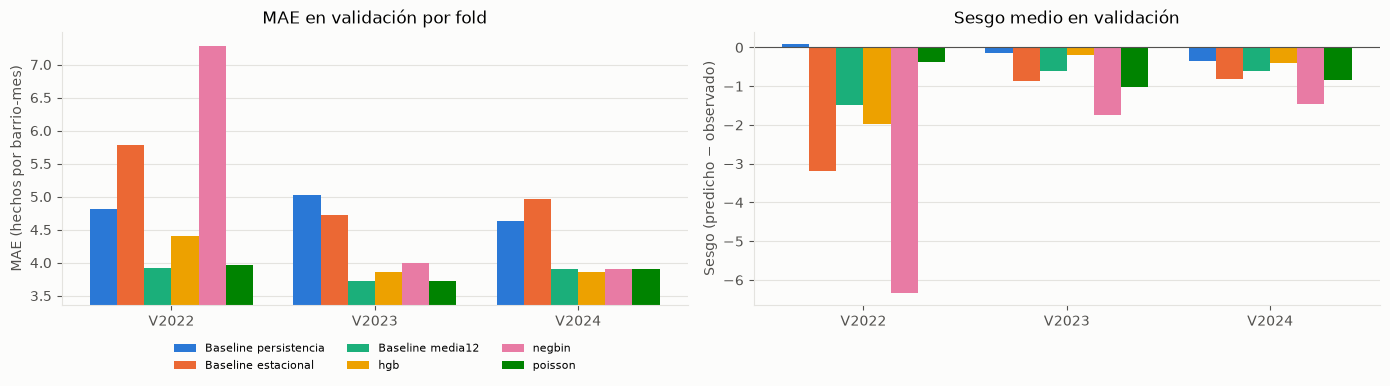

α NB2 por fold: {'conjunto=compacto,excluir_pandemia=False': [0.0807, 0.0785, 0.0638], 'conjunto=compacto,excluir_pandemia=True': [0.0236, 0.0315, 0.0274]}


In [5]:
# Diagnóstico en validación: MAE por fold de los mejores de cada familia frente a los baselines; sesgo; alfa de la NB
lab = {**{f"baseline:{b}": f"Baseline {b}" for b in R.BASELINES}, **{r: f"{fam}" for fam, r in best_by_fam["modelo"].items()}}
show = [f"baseline:{b}" for b in R.BASELINES] + list(best_by_fam["modelo"])
comp = pd.concat([base_val, grid_res])[lambda d: d["modelo"].isin(show)]
pv = comp.pivot(index="modelo", columns="fold", values="MAE").loc[show]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(3); w = .8 / len(show)
for i, mdl in enumerate(show):
    axes[0].bar(x + i * w - .4 + w / 2, pv.loc[mdl], width=w, color=CAT[i % len(CAT)], label=lab[mdl])
axes[0].set_xticks(x, pv.columns); axes[0].set_ylabel("MAE (hechos por barrio-mes)"); axes[0].set_title("MAE en validación por fold")
axes[0].legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.1)); axes[0].grid(axis="x", visible=False); axes[0].set_ylim(pv.values.min() * .9, pv.values.max() * 1.03)
sv = comp.pivot(index="modelo", columns="fold", values="sesgo").loc[show]
for i, mdl in enumerate(show):
    axes[1].bar(x + i * w - .4 + w / 2, sv.loc[mdl], width=w, color=CAT[i % len(CAT)])
axes[1].axhline(0, color=INK2, lw=.8); axes[1].set_xticks(x, sv.columns); axes[1].set_ylabel("Sesgo (predicho − observado)")
axes[1].set_title("Sesgo medio en validación"); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "validacion_mae_sesgo.png", dpi=150); plt.show()
nb_alpha = grid_res[(grid_res["familia"] == "negbin")].groupby("modelo")["alpha_nb"].apply(list).to_dict()
M["alpha_nb_por_fold"] = nb_alpha; print("α NB2 por fold:", {k.split("|")[1]: np.round(v, 4).tolist() for k, v in nb_alpha.items()})

**Lectura (3, validación).**
- **Baselines.** El mejor baseline es la **media de 12 meses** (MAE medio 3,850), muy por delante de la persistencia (4,823) y del estacional (5,157).
- **Selección.** Gana el **Poisson compacto con α = 0,1, sin meses de pandemia en el entrenamiento**, con un MAE medio de 3,863. Le ganan al baseline 2 de 3 *folds*, pero su MAE medio es 1,0035 veces el del baseline, lejos del umbral de 0,97. **No cumple el criterio de mejora.** El mejor HGB queda en 4,043 (1 *fold* ganado) y la NB2 sin regularizar del protocolo en 5,059.
- **Hiperparámetros.** Excluir los meses de pandemia del entrenamiento y regularizar son decisivos para el Poisson y el HGB. Para la NB2 sin regularizar del protocolo, excluirlos **empeora** el MAE (22,57 frente a 5,06) por la inestabilidad de V2022. Con la exclusión, V2022 entrena con solo 9 meses objetivo (enero y febrero de 2020 y junio a diciembre de 2021) y sin meses de marzo a mayo (revisión independiente, R4 y R14). Sin regularización, los GLM se vuelven inestables en V2022, que tiene pocos meses de entrenamiento y variables de nivel de ciudad colineales (§4b).
- **Sobredispersión.** Hay sobredispersión moderada: α de la NB2 entre 0,064 y 0,081, o entre 0,024 y 0,032 si se excluye la pandemia.
- **Sesgo.** Casi todos los modelos subestiman en promedio, por la tendencia de recuperación posterior a la pandemia (E1).

## 4. Evaluación principal en el test 2025 (gap = 0)

Esta sección lee la selección congelada. Se reajusta con todo el desarrollo (2020-01 a 2024-12) y se pronostica 2025 con origen rodante: cada mes usa la información observada hasta el mes anterior. También se informan, **sin uso para decidir**, el mejor modelo de cada familia y todos los baselines.

> **Qué hace la celda siguiente.** Lee la configuración congelada, la reentrena con todo 2020–2024 y pronostica cada mes de 2025 usando datos hasta el mes anterior. También calcula, solo para comparar, las referencias y el mejor modelo de cada familia.

In [6]:
frozen = json.loads((TAB / "seleccion_congelada.json").read_text(encoding="utf-8"))
cfgs = {name: next((k, p) for k, p in R.grid() if R.config_name(k, p) == name) for name in sorted(set(frozen["mejores_por_familia"].values()))}
test_rows, test_pred = [], X.loc[te_fin, ["barrio", "mes_objetivo", "y_target"] + list(R.BASELINES.values())].copy()
fitted = {}
for name, (k, p) in cfgs.items():
    trm = R.train_mask_excluding_pandemia(X, tr_fin, p["excluir_pandemia"])
    m = R.make_model(k, p).fit(X.loc[trm], X.loc[trm, "y_target"]); fitted[name] = m
    test_pred[name] = m.predict(X.loc[te_fin])
for b, col in R.BASELINES.items():
    test_pred[f"baseline:{b}"] = test_pred[col]
models_t = list(cfgs) + [f"baseline:{b}" for b in R.BASELINES]
tm = pd.DataFrame([{**regression_metrics(test_pred["y_target"], test_pred[mm]), "modelo": mm,
                    "seleccionado": mm == frozen["modelo_seleccionado"]} for mm in models_t]).sort_values("MAE")
test_pred.astype({"mes_objetivo": str}).to_csv(TAB / "predicciones_test.csv", index=False); tm.to_csv(TAB / "metricas_test.csv", index=False)
M["test"] = tm.to_dict(orient="records"); tm.round(4)

,MAE,RMSE,devianza_poisson,sesgo,n,modelo,seleccionado
5,4.0622,5.4696,1.4318,-0.8709,576,baseline:media12,False
0,4.0662,5.3636,1.3827,0.9478,576,"hgb|learning_rate=0.03,max_leaf_nodes=7,min_sa...",False
2,4.0708,5.5497,1.4785,-1.2208,576,"poisson|conjunto=compacto,alpha=0.1,excluir_pa...",True
1,4.1196,5.6558,1.5383,-1.4565,576,"negbin|conjunto=compacto,excluir_pandemia=False",False
3,5.0677,6.8765,2.6571,-0.0226,576,baseline:persistencia,False
4,5.4861,7.3203,3.2350,-1.7014,576,baseline:estacional,False


> **Qué hace la celda siguiente.** Mide la incertidumbre de la diferencia entre el modelo y cada referencia. Remuestrea bloques de 3 meses 2.000 veces para respetar que los meses consecutivos se parecen. **Qué mirar en la salida:** si el intervalo incluye el 0, la ventaja no es concluyente.

In [7]:
# IC por bloques (3 meses, 2.000 réplicas) de ΔMAE mensual = MAE(modelo) − MAE(baseline), sobre los 12 meses de 2025
sel_name, bb = frozen["modelo_seleccionado"], frozen["mejor_baseline"]
def dmae(a, b):
    d = test_pred.assign(_d=(test_pred[a] - test_pred["y_target"]).abs() - (test_pred[b] - test_pred["y_target"]).abs())
    return d.groupby("mes_objetivo")["_d"].mean()
boots = {}
for b in [f"baseline:{x}" for x in R.BASELINES]:
    boots[f"{sel_name.split('|')[0]} − {b}"] = block_bootstrap_ci(dmae(sel_name, b))
for name in cfgs:
    if name != sel_name:
        boots[f"{name.split('|')[0]} − {bb}"] = block_bootstrap_ci(dmae(name, bb))
bt = pd.DataFrame(boots).T.round(4); bt["IC_excluye_0_a_favor_del_modelo"] = bt["ic_sup"] < 0
bt.to_csv(TAB / "bootstrap_test.csv"); M["bootstrap_test"] = bt.reset_index().to_dict(orient="records")
crit_test = bool(bt.loc[f"{sel_name.split('|')[0]} − {bb}", "ic_sup"] < 0)
M["cumple_criterio_test"] = crit_test; print("¿Cumple el criterio en test (IC de ΔMAE frente al mejor baseline < 0)?", crit_test); bt

¿Cumple el criterio en test (IC de ΔMAE frente al mejor baseline < 0)? False


,media,ic_inf,ic_sup,bloque,reps,meses,IC_excluye_0_a_favor_del_modelo
poisson − baseline:persistencia,-0.9969,-1.4407,-0.5788,3.0,2000.0,12.0,True
poisson − baseline:estacional,-1.4153,-1.7962,-1.0930,3.0,2000.0,12.0,True
poisson − baseline:media12,0.0086,-0.1272,0.1422,3.0,2000.0,12.0,False
hgb − baseline:media12,0.0040,-0.2047,0.1902,3.0,2000.0,12.0,False
negbin − baseline:media12,0.0574,-0.0516,0.2848,3.0,2000.0,12.0,False


> **Qué hace la celda siguiente.** Evalúa si los intervalos de predicción de la binomial negativa contienen el valor real con la frecuencia prometida, y calcula el error por barrio y por mes.

In [8]:
# Intervalos de predicción de la NB2 (cobertura) y errores por barrio y mes
nb_name = frozen["mejores_por_familia"]["negbin"]; nbm = fitted[nb_name]
cov = {}
for lvl in (.8, .95):
    lo, hi = nbm.interval(X.loc[te_fin], lvl); y = X.loc[te_fin, "y_target"].to_numpy()
    cov[f"cobertura_{int(lvl*100)}"] = round(float(((y >= lo) & (y <= hi)).mean()), 3)
cov["alpha_nb_final"] = round(nbm.alpha_, 4); M["intervalos_nb_test"] = cov
e = test_pred.assign(err_sel=test_pred[sel_name] - test_pred["y_target"], err_base=test_pred[bb] - test_pred["y_target"])
pb = e.groupby("barrio").agg(y_media=("y_target", "mean"), MAE_sel=("err_sel", lambda s: s.abs().mean()), MAE_base=("err_base", lambda s: s.abs().mean()),
                              sesgo_sel=("err_sel", "mean"))
pb["dif_MAE"] = pb["MAE_sel"] - pb["MAE_base"]; pb["MAE_rel_sel"] = pb["MAE_sel"] / pb["y_media"]
pb.sort_values("MAE_sel", ascending=False).round(3).to_csv(TAB / "errores_por_barrio_test.csv")
M["por_barrio_test"] = {"barrios_mejora_vs_baseline": int((pb["dif_MAE"] < 0).sum()), "barrios": len(pb),
                        "spearman_MAE_vs_nivel": round(float(pb[["MAE_sel", "y_media"]].corr("spearman").iloc[0, 1]), 3),
                        "peores_MAE": pb["MAE_sel"].nlargest(3).round(2).to_dict()}
print(cov); print(M["por_barrio_test"])

{'cobertura_80': 0.858, 'cobertura_95': 0.983, 'alpha_nb_final': 0.0531}
{'barrios_mejora_vs_baseline': 20, 'barrios': 48, 'spearman_MAE_vs_nivel': 0.905, 'peores_MAE': {'Balvanera': 9.99, 'Caballito': 7.97, 'Saavedra': 7.19}}


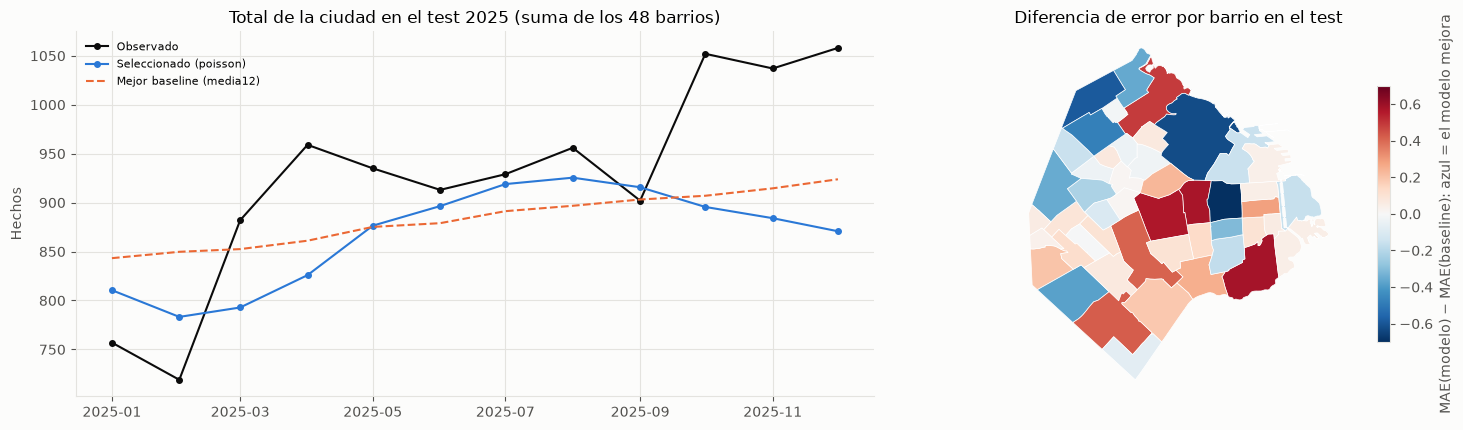

In [9]:
city = test_pred.groupby("mes_objetivo")[["y_target", sel_name, bb]].sum()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
xm = city.index.to_timestamp()
axes[0].plot(xm, city["y_target"], color=INK, marker="o", ms=4, label="Observado")
axes[0].plot(xm, city[sel_name], color=CAT[0], marker="o", ms=4, label=f"Seleccionado ({frozen['familia']})")
axes[0].plot(xm, city[bb], color=CAT[1], ls="--", label=f"Mejor baseline ({bb.split(':')[1]})")
axes[0].set_title("Total de la ciudad en el test 2025 (suma de los 48 barrios)"); axes[0].set_ylabel("Hechos"); axes[0].legend(frameon=False, fontsize=8)
g = gpd.read_file(ROOT / "data" / "raw" / "limites" / "barrios.geojson").rename(columns={"nombre": "barrio"}).merge(pb.reset_index(), on="barrio")
lim = float(np.abs(g["dif_MAE"]).max())
g.plot(column="dif_MAE", cmap="RdBu_r", vmin=-lim, vmax=lim, legend=True, ax=axes[1], edgecolor="white", lw=.5,
       legend_kwds={"shrink": .7, "label": "MAE(modelo) − MAE(baseline): azul = el modelo mejora"})
axes[1].set_axis_off(); axes[1].set_title("Diferencia de error por barrio en el test")
fig.tight_layout(); fig.savefig(FIG / "test_ciudad_y_barrios.png", dpi=150); plt.show()

**Lectura de la evaluación principal de 2025.**
- **Métricas.** El modelo seleccionado logra un MAE de **4,071**, frente a 4,062 de la media de 12 meses. La diferencia mensual es ΔMAE = +0,009, con IC 95 % por bloques **[−0,127; +0,142]**, que incluye el 0. **No se confirma una mejora** (H2 no respaldada frente a la media de 12 meses).
- **Contra baselines ingenuos.** Frente a la persistencia (ΔMAE −1,00; IC [−1,44; −0,58]) y al estacional (ΔMAE −1,42; IC [−1,80; −1,09]), la mejora es clara.
- **Total de la ciudad.** El modelo reproduce el bajo nivel de enero y febrero, que la media de 12 meses no capta, pero subestima el salto de octubre a diciembre de 2025.
- **Sesgo.** El sesgo es negativo en todos los GLM (de −1,22 a −1,46) y en la media de 12 meses (−0,87): 2025 fue el año con más hechos de la serie. El HGB, en cambio, sobreestima (+0,95) (revisión independiente, R4).
- **Por barrio.** El modelo mejora al baseline en 20 de los 48 barrios. El error crece con el nivel del barrio (Spearman 0,91); los mayores MAE están en Balvanera, Caballito y Saavedra.
- **Intervalos de la NB2 del protocolo.** Cobertura del 85,8 % y 98,3 % para niveles nominales de 80 % y 95 %: son conservadores.

## 4b. Análisis exploratorio post hoc de la binomial negativa con penalización L2

**Motivo (visible solo con la validación, §2).** Los GLM sin regularizar, entre ellos la NB2 del protocolo, se vuelven inestables en el *fold* V2022: tienen pocos meses de entrenamiento y las variables de nivel de ciudad son colineales. Ese *fold* llega a MAE de hasta 60, mientras que en V2023 y V2024 la NB rinde como el Poisson. La comparación entre familias exigida por el plan quedaba sesgada contra la NB.

**Corrección.** NB2 con α estimado por momentos y penalización L2, sin penalizar el intercepto (`NegBinNB2Reg`). Se prueban 8 configuraciones.

**Estatus.** Se agregó **después de ver el test**, así que **no es confirmatoria** y no reemplaza a la selección congelada. Queda registrada en el protocolo (sección 11).

In [10]:
ph = []
for k, p in R.grid_posthoc():
    name = R.config_name(k, p); maes = []
    for fo in folds:
        trm = R.train_mask_excluding_pandemia(X, fo["train"], p["excluir_pandemia"])
        maes.append(regression_metrics(X.loc[fo["val"], "y_target"], R.make_model(k, p).fit(X.loc[trm], X.loc[trm, "y_target"]).predict(X.loc[fo["val"]]))["MAE"])
    ph.append({"modelo": name, "V2022": maes[0], "V2023": maes[1], "V2024": maes[2], "MAE_media": float(np.mean(maes))})
ph = pd.DataFrame(ph).sort_values("MAE_media"); ph.to_csv(TAB / "posthoc_negbin_reg_validacion.csv", index=False)
best_ph = ph.iloc[0]; kph, pph = next((k, p) for k, p in R.grid_posthoc() if R.config_name(k, p) == best_ph["modelo"])
trm = R.train_mask_excluding_pandemia(X, tr_fin, pph["excluir_pandemia"])
mph = R.make_model(kph, pph).fit(X.loc[trm], X.loc[trm, "y_target"]); yph = mph.predict(X.loc[te_fin])
test_pred["posthoc:" + best_ph["modelo"]] = yph
covph = {}
for lvl in (.8, .95):
    lo, hi = mph.interval(X.loc[te_fin], lvl); yy = X.loc[te_fin, "y_target"].to_numpy(); covph[f"cobertura_{int(lvl*100)}"] = round(float(((yy >= lo) & (yy <= hi)).mean()), 3)
d = test_pred.assign(_d=(test_pred["posthoc:" + best_ph["modelo"]] - test_pred["y_target"]).abs() - (test_pred[bb] - test_pred["y_target"]).abs()).groupby("mes_objetivo")["_d"].mean()
M["posthoc_negbin_reg"] = {"mejor_validacion": best_ph["modelo"], "MAE_validacion_media": round(float(best_ph["MAE_media"]), 4),
                           "ratio_vs_mejor_baseline_validacion": round(float(best_ph["MAE_media"] / bv.loc[best_base, "MAE_media"]), 4),
                           "habria_ganado_la_seleccion": bool(best_ph["MAE_media"] < frozen["MAE_validacion_media"]),
                           "test": regression_metrics(X.loc[te_fin, "y_target"], yph), "alpha": round(mph.alpha_, 4), "cobertura_test": covph,
                           "bootstrap_vs_mejor_baseline": block_bootstrap_ci(d)}
print(json.dumps(M["posthoc_negbin_reg"], indent=1, ensure_ascii=False, default=str)); ph.round(4)

{
 "mejor_validacion": "negbin_reg|conjunto=compacto,lam=0.1,excluir_pandemia=True",
 "MAE_validacion_media": 3.864,
 "ratio_vs_mejor_baseline_validacion": 1.0037,
 "habria_ganado_la_seleccion": false,
 "test": {
  "MAE": 4.088475119852524,
  "RMSE": 5.577608370024561,
  "devianza_poisson": 1.493219770215551,
  "sesgo": -1.3102492058256996,
  "n": 576
 },
 "alpha": 0.022,
 "cobertura_test": {
  "cobertura_80": 0.818,
  "cobertura_95": 0.962
 },
 "bootstrap_vs_mejor_baseline": {
  "media": 0.026264471704375427,
  "ic_inf": -0.12847285881691872,
  "ic_sup": 0.17838055664635322,
  "bloque": 3,
  "reps": 2000,
  "meses": 12
 }
}


,modelo,V2022,V2023,V2024,MAE_media
5,"negbin_reg|conjunto=compacto,lam=0.1,excluir_p...",4.0135,3.6842,3.8943,3.8640
7,"negbin_reg|conjunto=compacto,lam=1.0,excluir_p...",4.1314,3.6844,3.9569,3.9242
6,"negbin_reg|conjunto=compacto,lam=1.0,excluir_p...",5.6851,3.9277,3.9049,4.5059
4,"negbin_reg|conjunto=compacto,lam=0.1,excluir_p...",6.8523,3.9633,3.8622,4.8926
2,"negbin_reg|conjunto=compacto,lam=0.01,excluir_...",7.2113,3.9969,3.8977,5.0353
0,"negbin_reg|conjunto=compacto,lam=0.001,excluir...",7.2539,3.9957,3.9035,5.0510
3,"negbin_reg|conjunto=compacto,lam=0.01,excluir_...",11.8389,3.7666,3.8943,6.5000
1,"negbin_reg|conjunto=compacto,lam=0.001,excluir...",45.3677,3.7945,3.8960,17.6861


## 5. Sensibilidad a la latencia de publicación (gap = 1)

Se usa la misma configuración seleccionada, con la información disponible solo hasta T−2. Los baselines también se recalculan con L = T−2. La evaluación de 2025 con gap = 1 es exploratoria y conserva la selección principal de gap = 0.

In [11]:
X1 = XG[1]; f1 = F.temporal_folds(X1); tr1, te1 = F.final_split(X1)
k, p = cfgs[sel_name]
rows = []
for fo in f1:
    trm = R.train_mask_excluding_pandemia(X1, fo["train"], p["excluir_pandemia"])
    yh = R.make_model(k, p).fit(X1.loc[trm], X1.loc[trm, "y_target"]).predict(X1.loc[fo["val"]])
    rows.append({"conjunto": "validación " + fo["fold"], "MAE_modelo": regression_metrics(X1.loc[fo["val"], "y_target"], yh)["MAE"],
                 "MAE_baseline": regression_metrics(X1.loc[fo["val"], "y_target"], X1.loc[fo["val"], R.BASELINES[bb.split(':')[1]]])["MAE"]})
trm = R.train_mask_excluding_pandemia(X1, tr1, p["excluir_pandemia"])
yh = R.make_model(k, p).fit(X1.loc[trm], X1.loc[trm, "y_target"]).predict(X1.loc[te1])
rows.append({"conjunto": "test 2025", "MAE_modelo": regression_metrics(X1.loc[te1, "y_target"], yh)["MAE"],
             "MAE_baseline": regression_metrics(X1.loc[te1, "y_target"], X1.loc[te1, R.BASELINES[bb.split(':')[1]]])["MAE"]})
g1 = pd.DataFrame(rows); g1["ratio"] = g1["MAE_modelo"] / g1["MAE_baseline"]
g1.to_csv(TAB / "sensibilidad_gap1.csv", index=False); M["gap1"] = g1.round(4).to_dict(orient="records"); g1.round(4)

,conjunto,MAE_modelo,MAE_baseline,ratio
0,validación V2022,4.9260,4.0234,1.2243
1,validación V2023,3.6749,3.7496,0.9801
2,validación V2024,3.9531,3.9300,1.0059
3,test 2025,4.2781,4.1674,1.0266


**Lectura (4b y 5).**
- **NB regularizada (post hoc, no confirmatoria).** La mejor configuración (λ = 0,1, sin meses de pandemia) tiene un MAE de validación de 3,864, igual al del seleccionado; no habría cambiado la selección. En test logra 4,088, con ΔMAE frente a la media de 12 meses de +0,026 (IC [−0,128; +0,178]). La cobertura observada en 2025 fue del 81,8 % y 96,2 % para niveles nominales del 80 % y 95 %. Confirmar su utilidad para estimar incertidumbre por barrio requiere un período independiente y un criterio de cobertura definido de antemano.
- **Latencia (gap = 1).** Las particiones ya están corregidas: con gap = 1, el ajuste solo usa las etiquetas disponibles al comenzar la evaluación, y diciembre del año anterior queda fuera. Con información solo hasta T−2, el modelo seleccionado queda **peor** que el baseline, también recalculado con T−2:
  - el cociente de MAE es **1,22 en V2022**, porque ese *fold* entrena con solo 7 meses fuera de la pandemia;
  - 0,98 en V2023 y 1,01 en V2024;
  - **1,03 en el test**.

  En esta sensibilidad, la media de 12 meses obtuvo un MAE menor en dos de los tres folds y en 2025.

## 6. Registro

> **Qué hace la celda siguiente.** Guarda todas las cifras del notebook en `regression_metrics.json`. El informe [docs/regression_report.md](../docs/regression_report.md) y la evaluación integrada (notebook 06) leen de ahí.

In [12]:
(TAB / "regression_metrics.json").write_text(json.dumps(M, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Guardado:", (TAB / "regression_metrics.json").relative_to(ROOT))

Guardado: reports\tables\03_regression\regression_metrics.json


### Conclusiones y qué pasa al paso siguiente

- **Respuesta a la pregunta.** Ningún modelo probado estima los hechos del mes siguiente mejor que el promedio de 12 meses, ni en la validación 2022–2024 ni en 2025. La hipótesis H2 no se respalda frente a esa referencia. Sí se superan con claridad las referencias ingenuas.
- **Qué se aprendió de los modelos.** Excluir la pandemia del entrenamiento y regularizar son decisivos para el Poisson seleccionado. Los GLM y la media de 12 meses subestiman 2025, el año con más hechos de la serie; el HGB lo sobreestima.
- **Límites.** Una sola temporada de prueba (2025, posiblemente con datos provisorios). Los errores son mayores en los barrios con más hechos. Con un mes más de demora en la publicación (*gap* = 1), el modelo queda por detrás del promedio.
- **Siguiente paso.** El notebook 04 plantea la misma pregunta como clasificación (¿qué barrios estarán en el top 10?), y el 06 compara las dos estrategias como herramientas de priorización.